In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuration du style des graphiques
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

In [2]:
# Chargement du jeu de données
df = pd.read_csv("all_data.csv")

# Inspection des premières lignes
print("--- Aperçu des données ---")
print(df.head())

# Dimensions du DataFrame
print(f"\nDimensions du jeu de données : {df.shape[0]} lignes, {df.shape[1]} colonnes")

# Liste des pays et des années analysés
print("\nPays inclus :", df["Country"].unique())
print("Années couvertes :", df["Year"].unique())

--- Aperçu des données ---
  Country  Year  Life expectancy at birth (years)           GDP
0   Chile  2000                              77.3  7.786093e+10
1   Chile  2001                              77.3  7.097992e+10
2   Chile  2002                              77.8  6.973681e+10
3   Chile  2003                              77.9  7.564346e+10
4   Chile  2004                              78.0  9.921039e+10

Dimensions du jeu de données : 96 lignes, 4 colonnes

Pays inclus : ['Chile' 'China' 'Germany' 'Mexico' 'United States of America' 'Zimbabwe']
Années couvertes : [2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013
 2014 2015]


In [4]:
# verification des valeurs manquantes et doublons
missing_values = df.isnull().sum()
print("\nValeurs manquantes par colonne :")
print(missing_values)
duplicated_values = df.duplicated().sum()
print("\nDoublons par colonne :")
print(duplicated_values)



Valeurs manquantes par colonne :
Country                             0
Year                                0
Life expectancy at birth (years)    0
GDP                                 0
dtype: int64

Doublons par colonne :
0


In [5]:
# Renommage de la colonne pour plus de sobriété
df = df.rename(columns={"Life expectancy at birth (years)": "LEABY"})

# Vérification des modifications et de la présence de valeurs manquantes
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Country  96 non-null     object 
 1   Year     96 non-null     int64  
 2   LEABY    96 non-null     float64
 3   GDP      96 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 3.1+ KB
None


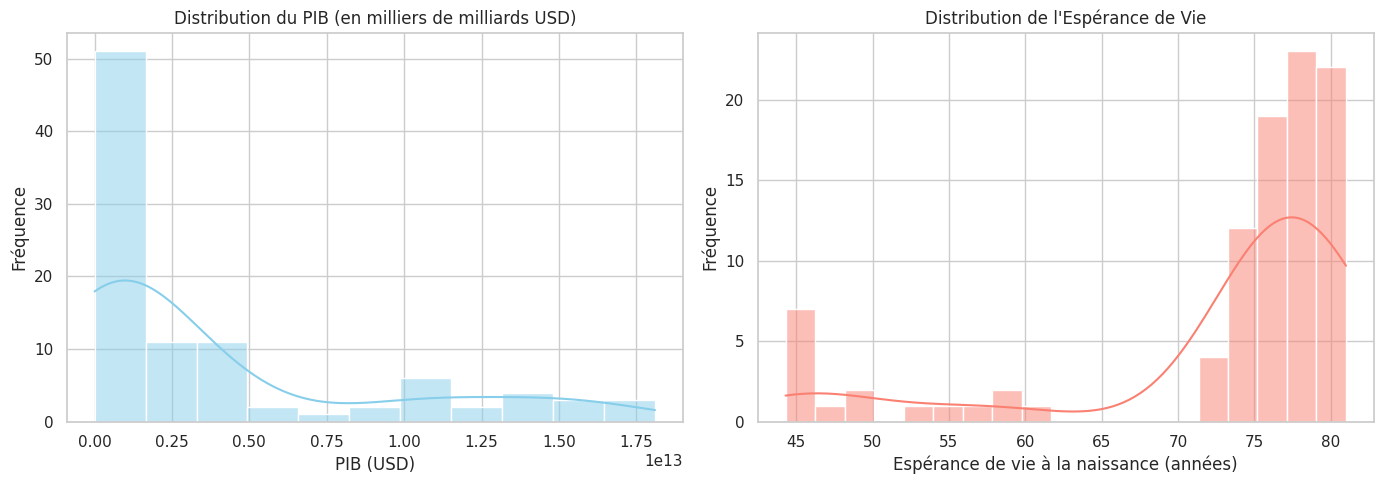

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution du PIB
sns.histplot(df["GDP"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Distribution du PIB (en milliers de milliards USD)")
axes[0].set_xlabel("PIB (USD)")
axes[0].set_ylabel("Fréquence")

# Distribution de l'Espérance de Vie
sns.histplot(df["LEABY"], kde=True, ax=axes[1], color="salmon")
axes[1].set_title("Distribution de l'Espérance de Vie")
axes[1].set_xlabel("Espérance de vie à la naissance (années)")
axes[1].set_ylabel("Fréquence")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1901/3948882986.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1901/3948882986.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


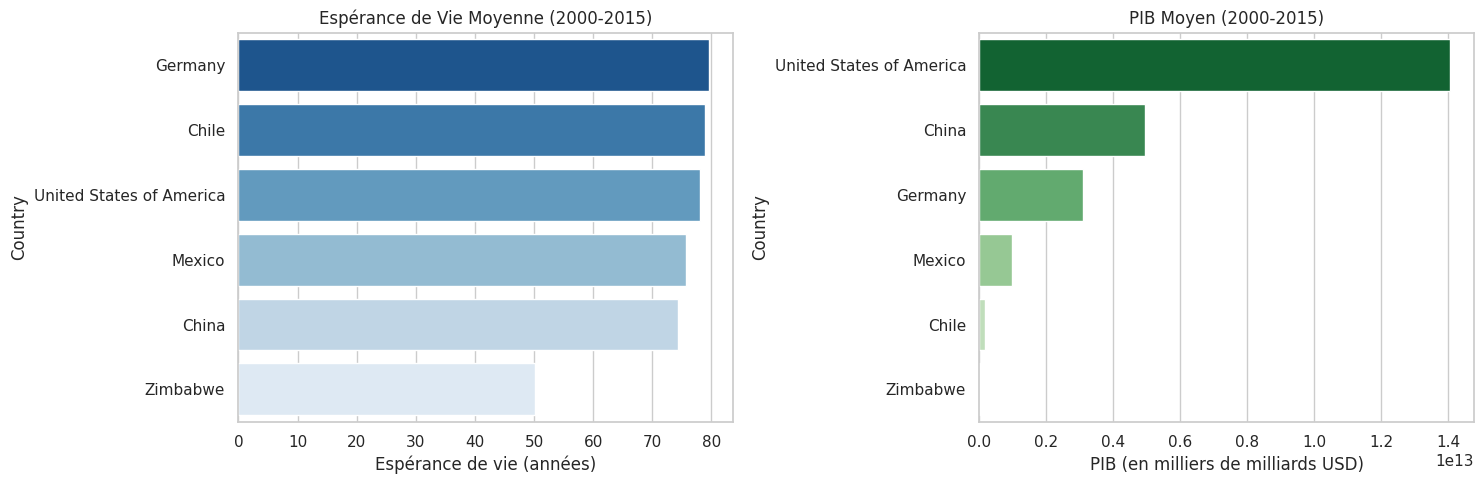

In [7]:
# Calcul des moyennes en excluant la colonne temporelle
df_means = df.drop(columns=["Year"]).groupby("Country").mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Moyenne de l'Espérance de vie par pays
sns.barplot(
    data=df_means.sort_values("LEABY", ascending=False),
    x="LEABY",
    y="Country",
    ax=axes[0],
    palette="Blues_r",
)
axes[0].set_title("Espérance de Vie Moyenne (2000-2015)")
axes[0].set_xlabel("Espérance de vie (années)")

# Moyenne du PIB par pays
sns.barplot(
    data=df_means.sort_values("GDP", ascending=False),
    x="GDP",
    y="Country",
    ax=axes[1],
    palette="Greens_r",
)
axes[1].set_title("PIB Moyen (2000-2015)")
axes[1].set_xlabel("PIB (en milliers de milliards USD)")

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 31.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 31.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 43.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 12.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


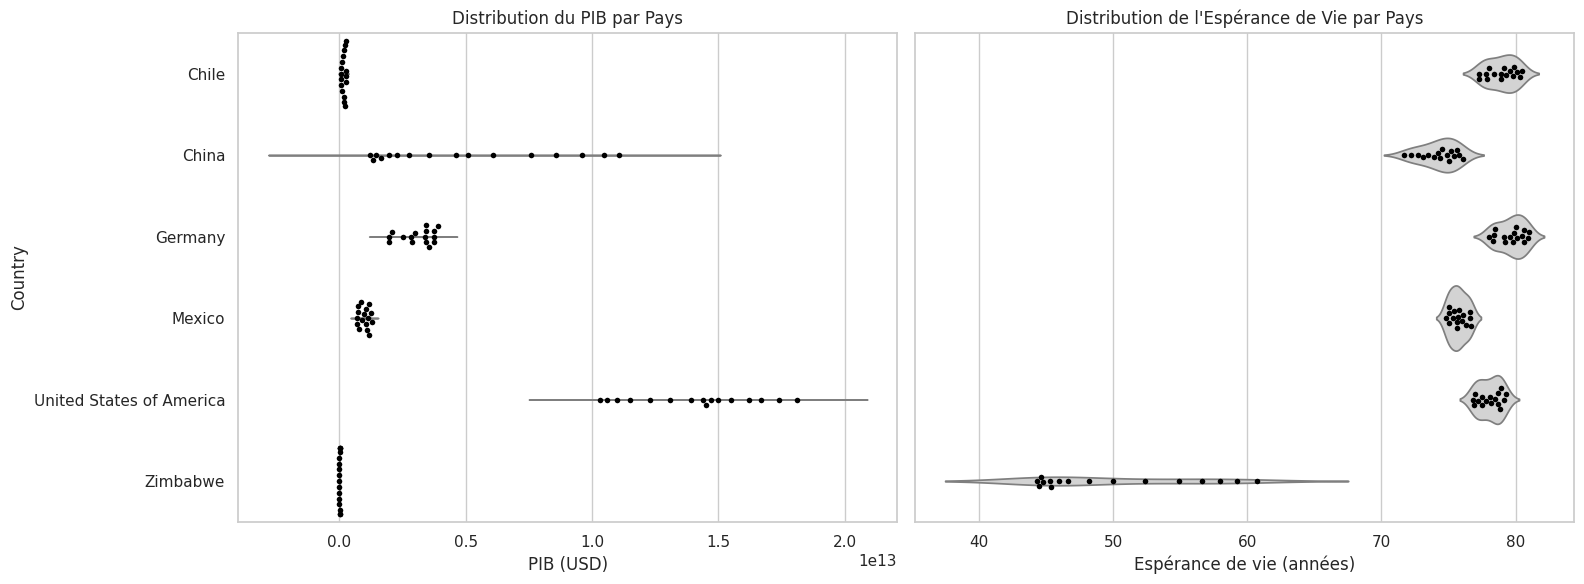

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Violin Plot + Swarm Plot pour le PIB
sns.violinplot(
    data=df, x="GDP", y="Country", ax=axes[0], color="lightgray", inner=None
)
sns.swarmplot(data=df, x="GDP", y="Country", ax=axes[0], size=4, color="black")
axes[0].set_title("Distribution du PIB par Pays")
axes[0].set_xlabel("PIB (USD)")

# Violin Plot + Swarm Plot pour l'Espérance de Vie
sns.violinplot(
    data=df, x="LEABY", y="Country", ax=axes[1], color="lightgray", inner=None
)
sns.swarmplot(
    data=df, x="LEABY", y="Country", ax=axes[1], size=4, color="black"
)
axes[1].set_title("Distribution de l'Espérance de Vie par Pays")
axes[1].set_xlabel("Espérance de vie (années)")

plt.tight_layout()
plt.show()

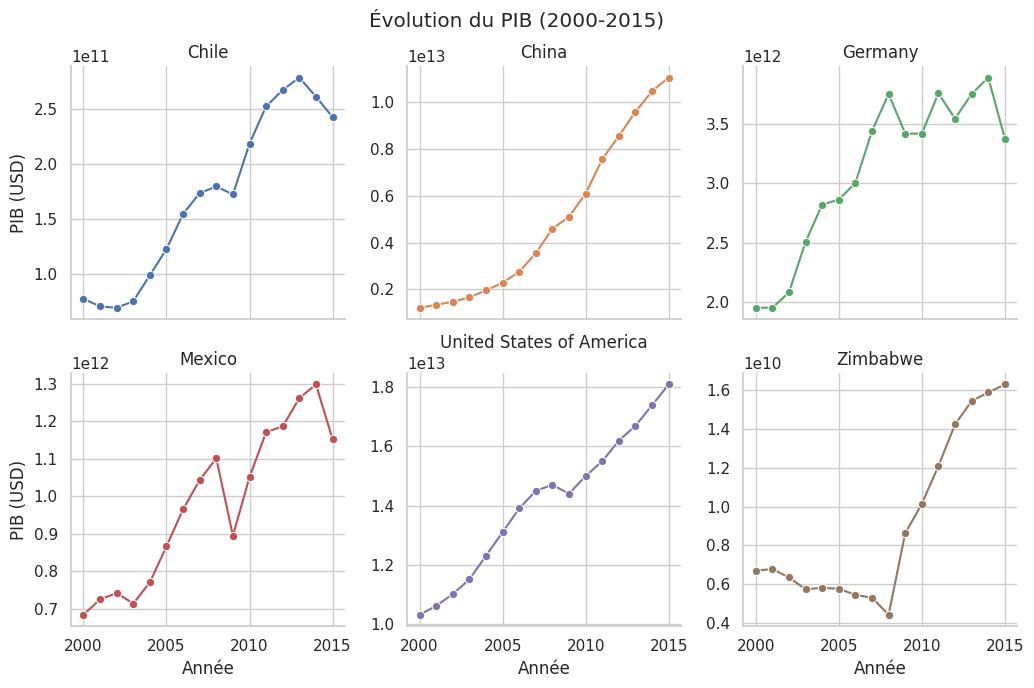

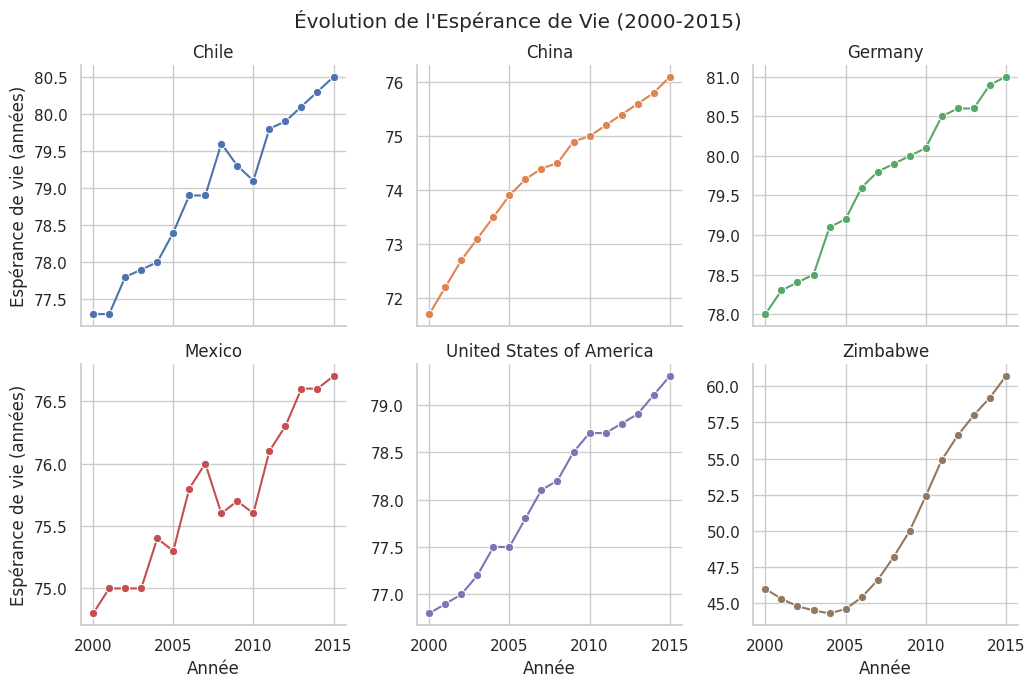

In [9]:
# Évolution temporelle du PIB par pays
graph_gdp = sns.FacetGrid(
    df, col="Country", col_wrap=3, hue="Country", sharey=False, height=3.5
)
graph_gdp.map(sns.lineplot, "Year", "GDP", marker="o")
graph_gdp.set_axis_labels("Année", "PIB (USD)")
graph_gdp.set_titles(col_template="{col_name}")
plt.subplots_adjust(top=0.9)
graph_gdp.fig.suptitle("Évolution du PIB (2000-2015)")
plt.show()

# Évolution temporelle de l'Espérance de Vie par pays
graph_leaby = sns.FacetGrid(
    df, col="Country", col_wrap=3, hue="Country", sharey=False, height=3.5
)
graph_leaby.map(sns.lineplot, "Year", "LEABY", marker="o")
graph_leaby.set_axis_labels("Année", "Espérance de vie (années)")
graph_leaby.set_titles(col_template="{col_name}")
plt.subplots_adjust(top=0.9)
graph_leaby.fig.suptitle("Évolution de l'Espérance de Vie (2000-2015)")
plt.show()

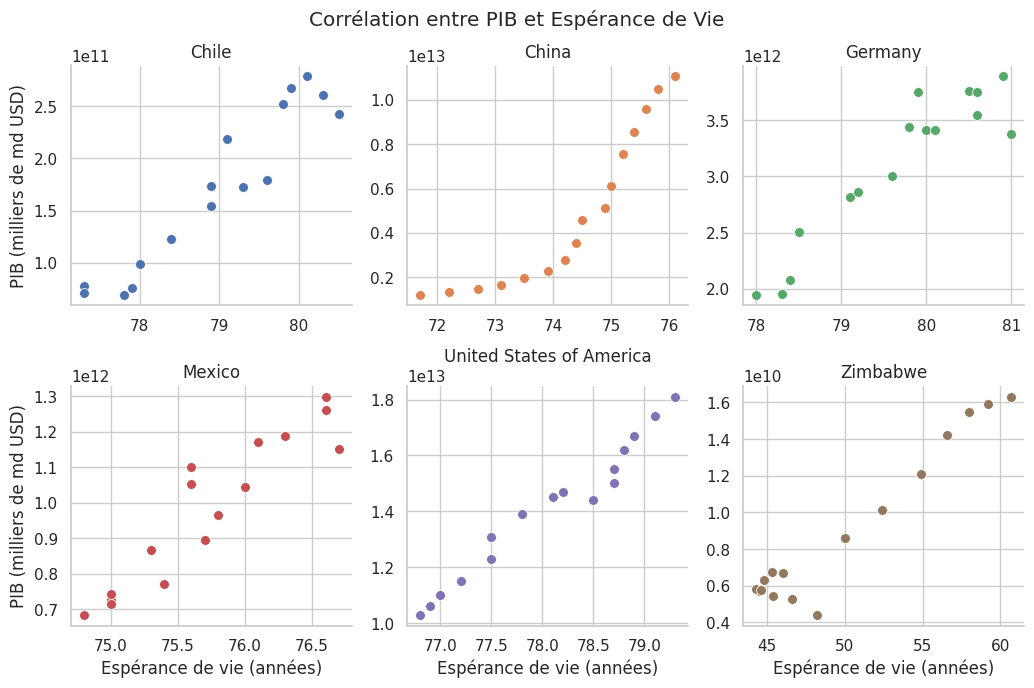

In [10]:
# Nuage de points facetté par pays
graph_corr = sns.FacetGrid(
    df,
    col="Country",
    col_wrap=3,
    hue="Country",
    sharey=False,
    sharex=False,
    height=3.5,
)
graph_corr.map(sns.scatterplot, "LEABY", "GDP", s=50)
graph_corr.set_axis_labels(
    "Espérance de vie (années)", "PIB (milliers de md USD)"
)
graph_corr.set_titles(col_template="{col_name}")
plt.subplots_adjust(top=0.9)
graph_corr.fig.suptitle("Corrélation entre PIB et Espérance de Vie")
plt.show()